<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/padv7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("\nDataset loaded successfully!")
print("\nFirst 5 Rows:")
print(df.head())


Dataset loaded successfully!

First 5 Rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [9]:
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())


Dataset Shape:
(20640, 9)

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.63948

In [10]:

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows:
0


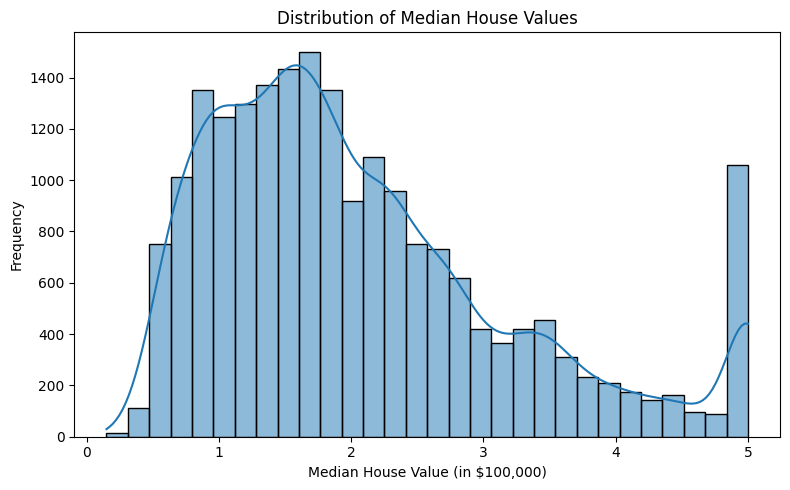

In [12]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    df['MedHouseVal'],
    bins=30,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (in $100,000)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

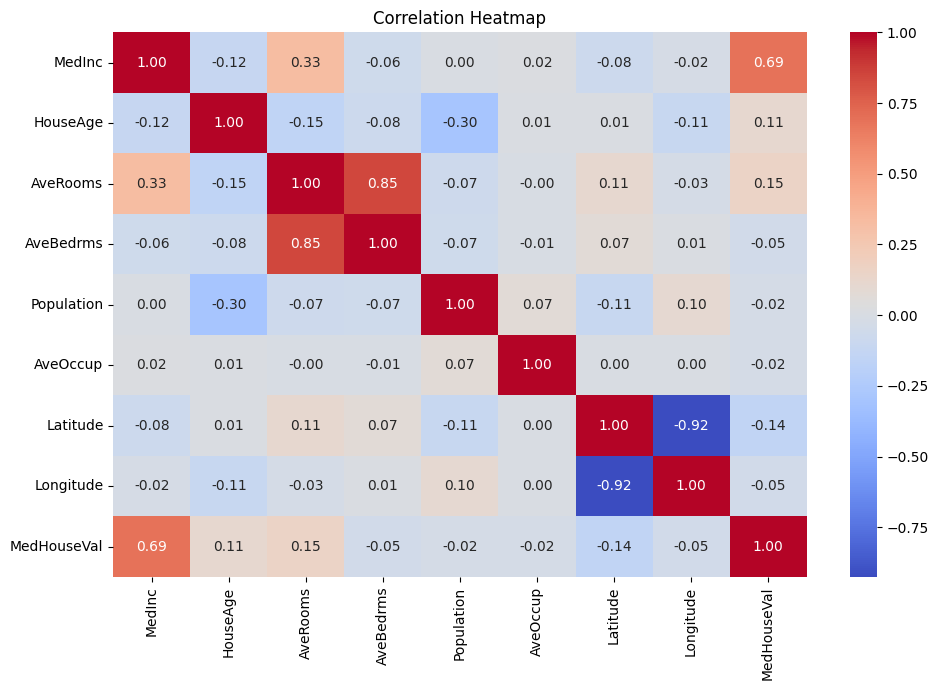

In [13]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [14]:
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Feature Shape: (20640, 8)
Target Shape: (20640,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


Training Samples: 16512
Testing Samples: 4128


In [16]:

model = LinearRegression()

model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [17]:
y_pred = model.predict(X_test)

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(np.round(y_pred[:10], 3))


First 10 Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 Predicted Values:
[0.719 1.764 2.71  2.839 2.605 2.012 2.646 2.169 2.741 3.916]


In [18]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n====================================")
print("REGRESSION MODEL EVALUATION")
print("====================================")

print(f"Mean Absolute Error (MAE): {mae:.4f}")

print(f"Mean Squared Error (MSE): {mse:.4f}")

print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

print(f"R2 Score: {r2:.4f}")

print("====================================")


REGRESSION MODEL EVALUATION
Mean Absolute Error (MAE): 0.5332
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R2 Score: 0.5758


In [19]:
results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_pred
})

print("\nActual vs Predicted Values:")
print(results.head(10).round(3))



Actual vs Predicted Values:
   Actual Values  Predicted Values
0          0.477             0.719
1          0.458             1.764
2          5.000             2.710
3          2.186             2.839
4          2.780             2.605
5          1.587             2.012
6          1.982             2.646
7          1.575             2.169
8          3.400             2.741
9          4.466             3.916


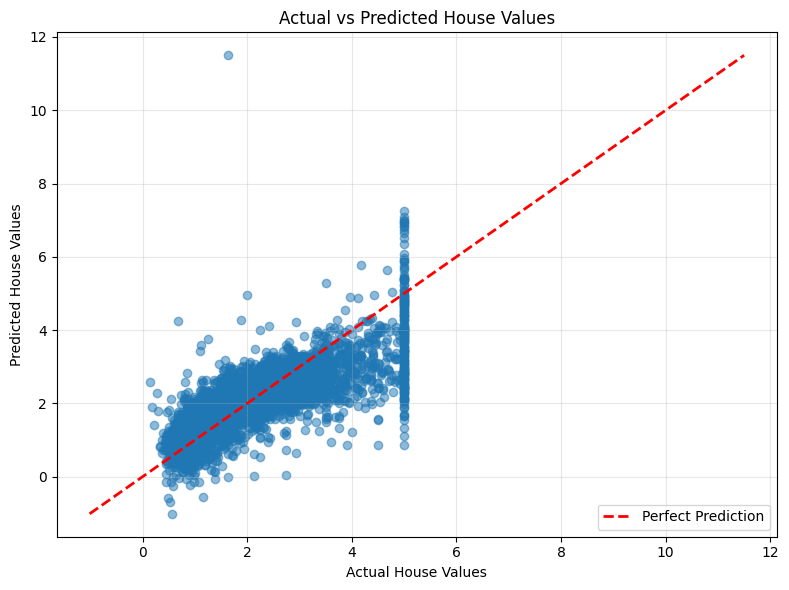

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")

plt.title("Actual vs Predicted House Values")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

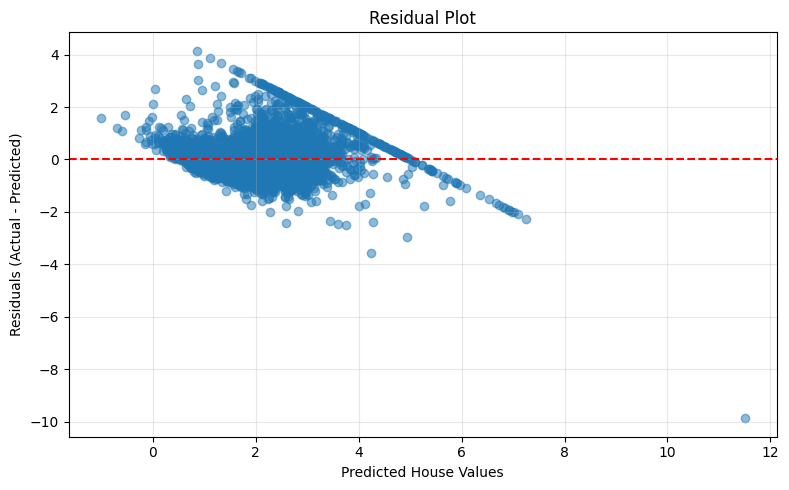

In [21]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals (Actual - Predicted)")

plt.title("Residual Plot")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

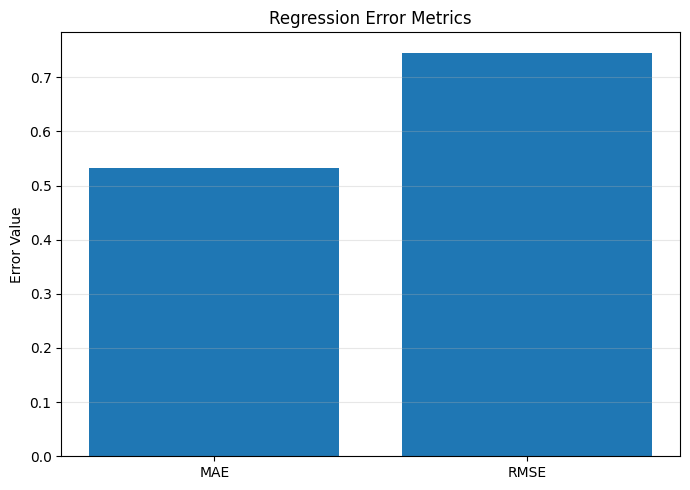

In [22]:
metrics = {
    'MAE': mae,
    'RMSE': rmse
}

plt.figure(figsize=(7, 5))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.title("Regression Error Metrics")
plt.ylabel("Error Value")

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



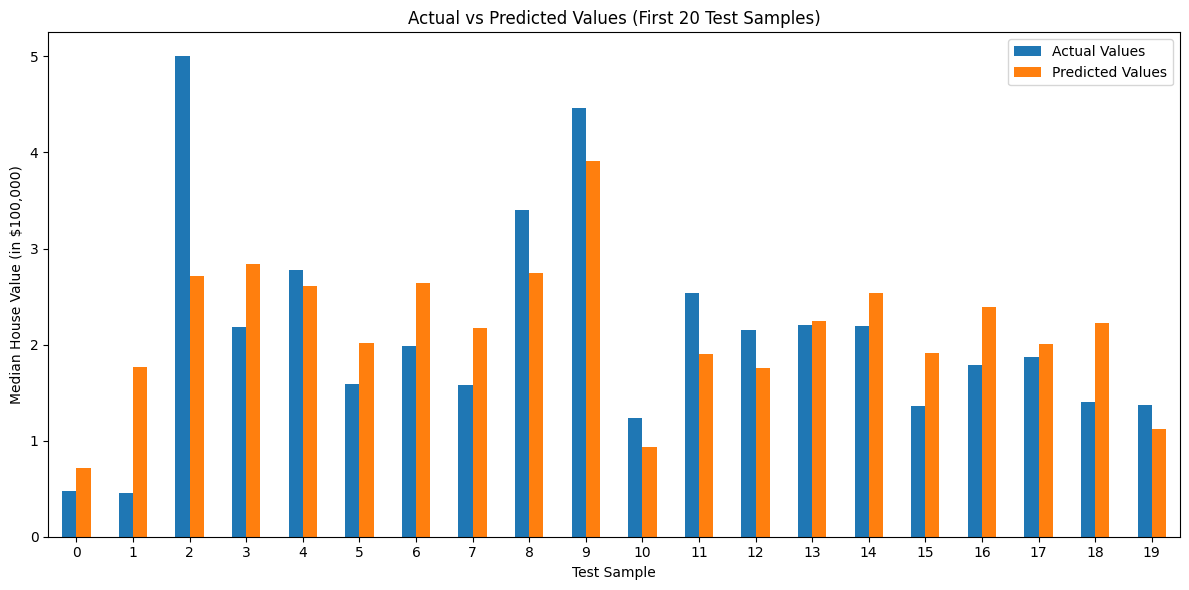

In [23]:
comparison = results.head(20)

comparison.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Actual vs Predicted Values (First 20 Test Samples)")
plt.xlabel("Test Sample")
plt.ylabel("Median House Value (in $100,000)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
print("\nFINAL MODEL INTERPRETATION")
print("---------------------------")

print(f"MAE  = {mae:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R2   = {r2:.4f}")

print("\nInterpretation:")

print(
    f"1. MAE: Predictions differ from actual values "
    f"by an average absolute error of {mae:.4f} "
    f"in units of $100,000."
)

print(
    f"2. RMSE: The root mean squared prediction error "
    f"is {rmse:.4f} in units of $100,000."
)

print(
    f"3. R2 Score: The model explains approximately "
    f"{r2 * 100:.2f}% of the variation in house values."
)

print("\nExperiment 8 Completed Successfully!")


FINAL MODEL INTERPRETATION
---------------------------
MAE  = 0.5332
RMSE = 0.7456
R2   = 0.5758

Interpretation:
1. MAE: Predictions differ from actual values by an average absolute error of 0.5332 in units of $100,000.
2. RMSE: The root mean squared prediction error is 0.7456 in units of $100,000.
3. R2 Score: The model explains approximately 57.58% of the variation in house values.

Experiment 8 Completed Successfully!
